# Practical 11: Continuous Predictive Modeling with Linear Regression

**UNIT 3: Preparing Big Data for Machine Learning**

**Problem Statement:** Write a Python program to build, train, and evaluate a Linear Regression model using Scikit-Learn. Fit the model to predict salary based on years of experience, display model coefficients (slope and intercept), predict outcomes on the test dataset, and calculate Mean Squared Error (MSE) and R-squared (R2) score.

,YearsExperience,Salary
0,1.0,35409.0
1,1.1,37067.0
2,1.1,36903.0
3,1.4,35032.0
4,1.5,40466.0


Train size: 30 | Test size: 10
Slope (coefficient): 8,628.14   -> salary rises by this much per extra year
Intercept           : 28,137.61
Equation            : Salary = 28,137.61 + 8,628.14 x Experience

,Experience,Actual,Predicted
0,6.1,85715.0,80769.0
1,5.1,74270.0,72141.0
2,4.3,64179.0,65239.0
3,7.8,94953.0,95437.0
4,1.5,40466.0,41080.0
5,3.8,56242.0,60925.0
6,11.1,123535.0,123910.0
7,7.9,99666.0,96300.0
8,12.0,131724.0,131675.0
9,2.8,46225.0,52296.0


MSE  : 10,098,802.17
RMSE : 3,177.86
R²   : 0.9884
Predicted salary for 6.5 years of experience: 84,221

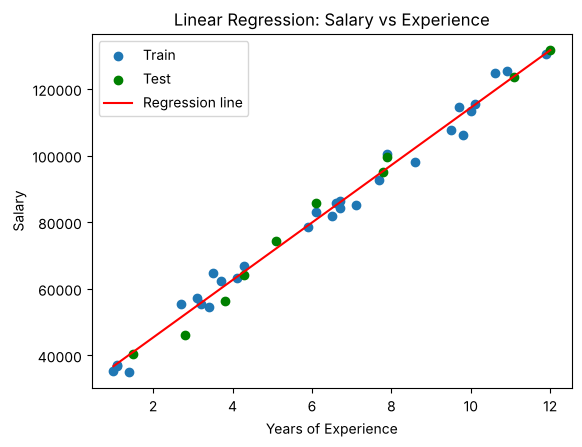

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

gen = np.random.default_rng(7)
n = 40
yrs = np.sort(np.round(gen.uniform(1, 12, n), 1))
salary = np.round(27000 + 8800 * yrs + gen.normal(0, 3500, n), 0)
orders = pd.DataFrame({"YearsExperience": yrs, "Salary": salary})
print(orders.head())

X = orders[["YearsExperience"]]
y = orders["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train size:", len(X_train), "| Test size:", len(X_test))

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Slope (coefficient): {model.coef_[0]:,.2f}   -> salary rises by this much per extra year")
print(f"Intercept           : {model.intercept_:,.2f}")
print(f"Equation            : Salary = {model.intercept_:,.2f} + {model.coef_[0]:,.2f} x Experience")

y_pred = model.predict(X_test)
comparison = pd.DataFrame({"Experience": X_test["YearsExperience"].values,
                           "Actual": y_test.values,
                           "Predicted": y_pred.round(0)})
print(comparison)

mse = mean_squared_error(y_test, y_pred)
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {np.sqrt(mse):,.2f}")
print(f"R²   : {r2_score(y_test, y_pred):.4f}")

new = pd.DataFrame({"YearsExperience": [6.5]})
print(f"Predicted salary for 6.5 years of experience: {model.predict(new)[0]:,.0f}")

plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, color="green", label="Test")
plt.plot(X, model.predict(X), color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Salary vs Experience")
plt.legend()
plt.show()